# 03 retention strategy



In [1]:
from IPython.display import display
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

# Locate the project from its root or a subdirectory such as notebooks.
project_dir = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "data" / "processed" / "customer_master.csv").is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Open this notebook from the project root or its notebooks folder. "
        "The project must contain data/processed/customer_master.csv."
    )
print("Project directory:", project_dir)


processed_dir = project_dir / "data" / "processed"
model_dir = project_dir / "models"
image_dir = project_dir / "images"
image_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    processed_dir / "customer_master.csv",
    dtype={"customer_id": "string"},
    na_values=["NULL"]
)

split_assignments = pd.read_csv(
    processed_dir / "model_split_assignments.csv",
    dtype={"customer_id": "string"}
)

with open(
    model_dir / "model_metadata.json",
    "r",
    encoding="utf-8"
) as file:
    metadata = json.load(file)

assert sklearn.__version__ == metadata["sklearn_version"], (
    "scikit-learn version differs from the saved model environment."
)

model = joblib.load(
    model_dir / "random_forest_pipeline.joblib"
)

assert df["customer_id"].notna().all()
assert df["customer_id"].is_unique
assert split_assignments["customer_id"].is_unique
assert set(df["customer_id"]) == set(split_assignments["customer_id"])

customers = df.merge(
    split_assignments,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

assert customers["split"].isin(
    ["train", "validation", "test"]
).all()

feature_columns = metadata["feature_columns"]
risk_threshold = float(metadata["threshold"])

assert set(feature_columns).issubset(customers.columns)
assert not {"customer_id", "churn", "churn_flag"}.intersection(
    feature_columns
)

print("Model:", metadata["model_name"])
print("Risk threshold:", risk_threshold)
print("Total customers:", len(customers))
print("Non-churned customers:", customers["churn"].eq("No").sum())

print("\nCustomers by split:")
print(customers["split"].value_counts())

print("\nModel and input files loaded successfully.")

Project directory: C:\Users\21129\Desktop\硕士申请材料\telecom-churn-retention-analysis
Model: Random Forest
Risk threshold: 0.35
Total customers: 7043
Non-churned customers: 5174

Customers by split:
split
train         4225
validation    1409
test          1409
Name: count, dtype: int64

Model and input files loaded successfully.


In [2]:
positive_class_index = list(model.classes_).index(1)

customers["model_score"] = model.predict_proba(
    customers[feature_columns]
)[:, positive_class_index]

customers["score_scope"] = customers["split"].map({
    "train": "In-sample",
    "validation": "Validation-used",
    "test": "Held-out"
})

active_customers = (
    customers.loc[customers["churn"].eq("No")]
    .copy()
    .sort_values(
        ["monthly_charges", "customer_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

assert active_customers["monthly_charges"].notna().all()

top_customer_count = int(
    np.ceil(len(active_customers) * 0.20)
)

active_customers["monthly_charge_rank"] = (
    np.arange(1, len(active_customers) + 1)
)

active_customers["high_value"] = (
    active_customers["monthly_charge_rank"] <= top_customer_count
)

active_customers["high_risk"] = (
    active_customers["model_score"] >= risk_threshold
)

segment_order = [
    "Higher risk / High value",
    "Higher risk / Other value",
    "Lower risk / High value",
    "Lower risk / Other value"
]

active_customers["segment"] = np.select(
    [
        active_customers["high_risk"] & active_customers["high_value"],
        active_customers["high_risk"] & ~active_customers["high_value"],
        ~active_customers["high_risk"] & active_customers["high_value"]
    ],
    segment_order[:3],
    default=segment_order[3]
)

segment_summary = (
    active_customers.groupby("segment")
    .agg(
        customer_count=("customer_id", "size"),
        average_model_score=("model_score", "mean"),
        average_monthly_charges=("monthly_charges", "mean"),
        monthly_charge_total=("monthly_charges", "sum")
    )
    .reindex(segment_order)
)

segment_summary["customer_share"] = (
    segment_summary["customer_count"] / len(active_customers)
)

segment_summary["monthly_charge_share"] = (
    segment_summary["monthly_charge_total"]
    / active_customers["monthly_charges"].sum()
)

assert segment_summary["customer_count"].sum() == 5174
assert active_customers["high_value"].sum() == 1035

print("Non-churned customers:", len(active_customers))
print("High-value customers:", top_customer_count)
print("Risk score threshold:", risk_threshold)

display(
    segment_summary.style.format({
        "customer_count": "{:,}",
        "average_model_score": "{:.2%}",
        "average_monthly_charges": "{:,.2f}",
        "monthly_charge_total": "{:,.2f}",
        "customer_share": "{:.2%}",
        "monthly_charge_share": "{:.2%}"
    })
)

print("\nSegment counts by original split:")

display(
    pd.crosstab(
        active_customers["segment"],
        active_customers["split"]
    ).reindex(
        index=segment_order,
        columns=["train", "validation", "test"],
        fill_value=0
    )
)

Non-churned customers: 5174
High-value customers: 1035
Risk score threshold: 0.35


,customer_count,average_model_score,average_monthly_charges,monthly_charge_total,customer_share,monthly_charge_share
segment,,,,,,
Higher risk / High value,205,50.08%,99.32,"20,361.10",3.96%,6.42%
Higher risk / Other value,681,50.33%,65.87,"44,858.95",13.16%,14.15%
Lower risk / High value,830,15.68%,104.05,"86,363.40",16.04%,27.25%
Lower risk / Other value,"3,458",9.64%,47.83,"165,402.30",66.83%,52.18%



Segment counts by original split:


split,train,validation,test
segment,,,
Higher risk / High value,108,53,44
Higher risk / Other value,363,159,159
Lower risk / High value,529,152,149
Lower risk / Other value,2104,671,683


In [3]:
priority_customers = active_customers.loc[
    active_customers["segment"].eq("Higher risk / High value")
].copy()

profile_features = [
    "contract",
    "internet_service",
    "payment_method"
]

profile_tables = []

for feature in profile_features:
    all_counts = active_customers[feature].value_counts()
    priority_counts = priority_customers[feature].value_counts()

    profile = pd.DataFrame({
        "all_active_count": all_counts,
        "priority_count": priority_counts
    }).fillna(0).astype(int)

    profile["all_active_share"] = (
        profile["all_active_count"] / len(active_customers)
    )
    profile["priority_share"] = (
        profile["priority_count"] / len(priority_customers)
    )
    profile["share_difference_pp"] = (
        profile["priority_share"] - profile["all_active_share"]
    ) * 100

    profile.index.name = "category"
    profile = profile.reset_index()
    profile.insert(0, "attribute", feature)
    profile_tables.append(profile)

priority_profile = pd.concat(
    profile_tables,
    ignore_index=True
)

display(
    priority_profile.style.format({
        "all_active_count": "{:,}",
        "priority_count": "{:,}",
        "all_active_share": "{:.2%}",
        "priority_share": "{:.2%}",
        "share_difference_pp": "{:+.2f}"
    })
)

numeric_profile = pd.DataFrame({
    "All non-churned customers": active_customers[
        ["tenure_months", "monthly_charges"]
    ].median(),
    "Priority candidate group": priority_customers[
        ["tenure_months", "monthly_charges"]
    ].median()
})

numeric_profile.index = [
    "Median tenure (months)",
    "Median monthly charges"
]

display(numeric_profile.style.format("{:.2f}"))

print("Priority candidate count:", len(priority_customers))
print("Profile describes model-selected customers, not causal drivers.")

,attribute,category,all_active_count,priority_count,all_active_share,priority_share,share_difference_pp
0,contract,Month-to-month,"2,220",200,42.91%,97.56%,+54.65
1,contract,One year,"1,307",5,25.26%,2.44%,-22.82
2,contract,Two year,"1,647",0,31.83%,0.00%,-31.83
3,internet_service,DSL,"1,962",0,37.92%,0.00%,-37.92
4,internet_service,Fiber optic,"1,799",205,34.77%,100.00%,+65.23
5,internet_service,No,"1,413",0,27.31%,0.00%,-27.31
6,payment_method,Bank transfer (automatic),"1,286",31,24.86%,15.12%,-9.73
7,payment_method,Credit card (automatic),"1,290",24,24.93%,11.71%,-13.23
8,payment_method,Electronic check,"1,294",138,25.01%,67.32%,+42.31
9,payment_method,Mailed check,"1,304",12,25.20%,5.85%,-19.35


,All non-churned customers,Priority candidate group
Median tenure (months),38.00,31.00
Median monthly charges,64.43,99.65


Priority candidate count: 205
Profile describes model-selected customers, not causal drivers.


In [4]:
contact_cost_per_customer = 5.0
offer_cost_per_customer = 10.0
retained_months = 6
contribution_margin = 0.40

scenario_uplifts = {
    "Low uplift": 0.02,
    "Base uplift": 0.05,
    "High uplift": 0.10
}

candidate_count = len(priority_customers)
candidate_monthly_charges = (
    priority_customers["monthly_charges"].sum()
)

campaign_cost = candidate_count * (
    contact_cost_per_customer + offer_cost_per_customer
)

contribution_if_all_incrementally_retained = (
    candidate_monthly_charges
    * retained_months
    * contribution_margin
)

roi_rows = []

for scenario, uplift in scenario_uplifts.items():
    incremental_customers = candidate_count * uplift

    incremental_contribution = (
        contribution_if_all_incrementally_retained * uplift
    )

    net_benefit = incremental_contribution - campaign_cost

    roi_rows.append({
        "scenario": scenario,
        "assumed_incremental_retention": uplift,
        "contacted_customers": candidate_count,
        "expected_incremental_customers": incremental_customers,
        "incremental_contribution": incremental_contribution,
        "campaign_cost": campaign_cost,
        "net_benefit": net_benefit,
        "roi": net_benefit / campaign_cost
    })

roi_scenarios = pd.DataFrame(roi_rows).set_index("scenario")

break_even_uplift = (
    campaign_cost / contribution_if_all_incrementally_retained
)

display(
    roi_scenarios.style.format({
        "assumed_incremental_retention": "{:.1%}",
        "contacted_customers": "{:,}",
        "expected_incremental_customers": "{:.2f}",
        "incremental_contribution": "{:,.2f}",
        "campaign_cost": "{:,.2f}",
        "net_benefit": "{:,.2f}",
        "roi": "{:.2%}"
    })
)

print(f"Break-even incremental retention: {break_even_uplift:.2%}")
print("All campaign inputs are illustrative assumptions.")
print("Model scores select candidates; they are not used as future probabilities.")

,assumed_incremental_retention,contacted_customers,expected_incremental_customers,incremental_contribution,campaign_cost,net_benefit,roi
scenario,,,,,,,
Low uplift,2.0%,205,4.10,977.33,"3,075.00","-2,097.67",-68.22%
Base uplift,5.0%,205,10.25,"2,443.33","3,075.00",-631.67,-20.54%
High uplift,10.0%,205,20.50,"4,886.66","3,075.00","1,811.66",58.92%


Break-even incremental retention: 6.29%
All campaign inputs are illustrative assumptions.
Model scores select candidates; they are not used as future probabilities.


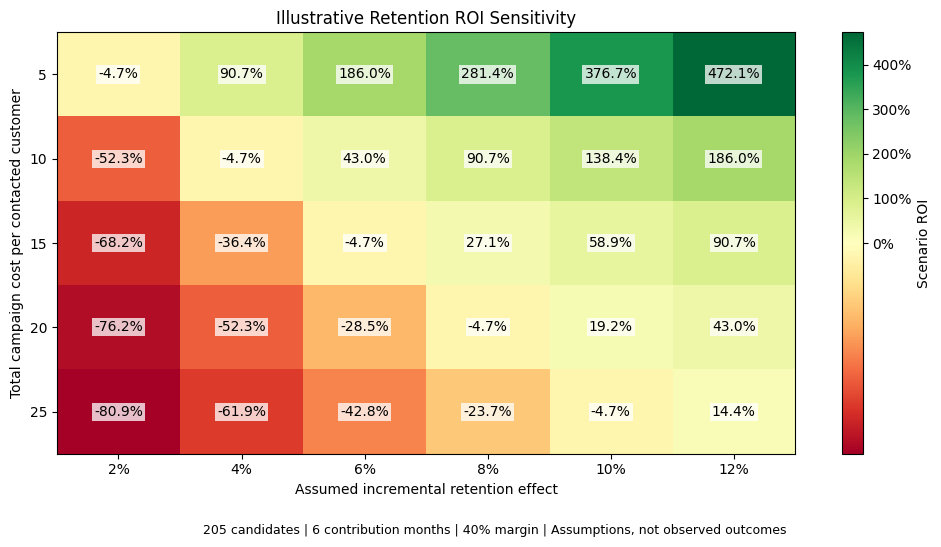

In [5]:
uplift_values = np.array([0.02, 0.04, 0.06, 0.08, 0.10, 0.12])
cost_values = np.array([5.0, 10.0, 15.0, 20.0, 25.0])

sensitivity_rows = []

for cost in cost_values:
    for uplift in uplift_values:
        total_cost = candidate_count * cost
        contribution = (
            contribution_if_all_incrementally_retained * uplift
        )
        net_benefit = contribution - total_cost

        sensitivity_rows.append({
            "cost_per_customer": cost,
            "assumed_incremental_retention": uplift,
            "campaign_cost": total_cost,
            "incremental_contribution": contribution,
            "net_benefit": net_benefit,
            "roi": net_benefit / total_cost
        })

roi_sensitivity = pd.DataFrame(sensitivity_rows)

roi_matrix = roi_sensitivity.pivot(
    index="cost_per_customer",
    columns="assumed_incremental_retention",
    values="roi"
).reindex(
    index=cost_values,
    columns=uplift_values
)

from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(10, 5.5))

heatmap = ax.imshow(
    roi_matrix.to_numpy(),
    cmap="RdYlGn",
    norm=TwoSlopeNorm(
        vmin=roi_matrix.to_numpy().min(),
        vcenter=0,
        vmax=roi_matrix.to_numpy().max()
    ),
    aspect="auto"
)

ax.set_xticks(
    np.arange(len(uplift_values)),
    labels=[f"{value:.0%}" for value in uplift_values]
)
ax.set_yticks(
    np.arange(len(cost_values)),
    labels=[f"{value:.0f}" for value in cost_values]
)

for row in range(len(cost_values)):
    for column in range(len(uplift_values)):
        ax.text(
            column,
            row,
            f"{roi_matrix.iloc[row, column]:.1%}",
            ha="center",
            va="center",
            fontsize=10,
            color="black",
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.75,
                "pad": 1.5
            }
        )

ax.set_title("Illustrative Retention ROI Sensitivity")
ax.set_xlabel("Assumed incremental retention effect")
ax.set_ylabel("Total campaign cost per contacted customer")

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Scenario ROI")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1.0))

fig.text(
    0.5,
    0.02,
    "205 candidates | 6 contribution months | 40% margin | "
    "Assumptions, not observed outcomes",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.06, 1, 1])

fig.savefig(
    image_dir / "11_retention_roi_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

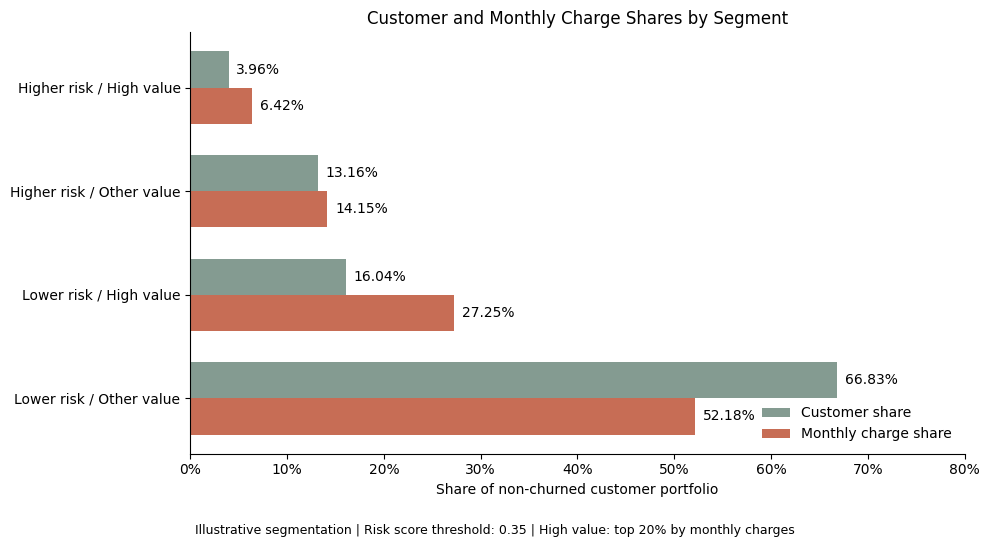

In [6]:
plot_labels = [
    "Higher risk / High value",
    "Higher risk / Other value",
    "Lower risk / High value",
    "Lower risk / Other value"
]

positions = np.arange(len(segment_order))
bar_height = 0.35

fig, ax = plt.subplots(figsize=(10, 5.5))

customer_bars = ax.barh(
    positions - bar_height / 2,
    segment_summary.loc[segment_order, "customer_share"],
    height=bar_height,
    color="#849B91",
    label="Customer share"
)

charge_bars = ax.barh(
    positions + bar_height / 2,
    segment_summary.loc[segment_order, "monthly_charge_share"],
    height=bar_height,
    color="#C76D55",
    label="Monthly charge share"
)

for bars in [customer_bars, charge_bars]:
    for bar in bars:
        ax.text(
            bar.get_width() + 0.008,
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2%}",
            va="center",
            fontsize=10
        )

ax.set_yticks(positions, labels=plot_labels)
ax.invert_yaxis()
ax.set_xlim(0, 0.80)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Share of non-churned customer portfolio")
ax.set_title("Customer and Monthly Charge Shares by Segment")
ax.legend(frameon=False, loc="lower right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.5,
    0.02,
    "Illustrative segmentation | Risk score threshold: 0.35 | "
    "High value: top 20% by monthly charges",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.06, 1, 1])

fig.savefig(
    image_dir / "12_customer_segment_shares.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
processed_dir.mkdir(parents=True, exist_ok=True)

assert active_customers["customer_id"].is_unique
assert len(active_customers) == 5174
assert len(priority_customers) == 205
assert np.isclose(
    segment_summary["monthly_charge_total"].sum(),
    active_customers["monthly_charges"].sum()
)

active_export = active_customers.copy()
active_export["risk_threshold"] = risk_threshold
active_export["high_value_rule"] = (
    "Top 20% of non-churned customers by monthly charges; "
    "ties ordered by customer_id"
)

priority_export = active_export.loc[
    active_export["segment"].eq("Higher risk / High value")
].copy()

segment_export = segment_summary.reset_index()

split_segment_export = (
    active_customers.groupby(
        ["segment", "split", "score_scope"],
        observed=True
    )
    .agg(
        customer_count=("customer_id", "size"),
        monthly_charge_total=("monthly_charges", "sum"),
        average_model_score=("model_score", "mean")
    )
    .reset_index()
)

roi_export = roi_scenarios.reset_index()
roi_export["contact_cost_per_customer"] = contact_cost_per_customer
roi_export["offer_cost_per_customer"] = offer_cost_per_customer
roi_export["retained_months"] = retained_months
roi_export["contribution_margin"] = contribution_margin
roi_export["break_even_uplift"] = break_even_uplift
roi_export["candidate_segment"] = "Higher risk / High value"
roi_export["analysis_type"] = "Illustrative scenario"

sensitivity_export = roi_sensitivity.copy()
sensitivity_export["contacted_customers"] = len(priority_customers)
sensitivity_export["retained_months"] = retained_months
sensitivity_export["contribution_margin"] = contribution_margin
sensitivity_export["candidate_segment"] = "Higher risk / High value"
sensitivity_export["analysis_type"] = "Illustrative scenario"

export_tables = {
    "active_customer_segments.csv": active_export,
    "priority_customer_candidates.csv": priority_export,
    "customer_segment_summary.csv": segment_export,
    "customer_segment_by_split.csv": split_segment_export,
    "priority_customer_profile.csv": priority_profile,
    "retention_roi_scenarios.csv": roi_export,
    "retention_roi_sensitivity.csv": sensitivity_export
}

for filename, table in export_tables.items():
    table.to_csv(
        processed_dir / filename,
        index=False,
        encoding="utf-8-sig"
    )
    print(f"Saved {filename}: {len(table):,} rows")

assumptions = {
    "analysis_type": "Illustrative retention strategy",
    "candidate_segment": "Higher risk / High value",
    "candidate_count": len(priority_customers),
    "risk_threshold": risk_threshold,
    "high_value_rule": (
        "Top 20% of non-churned customers by monthly charges, "
        "rounded up; ties ordered by customer_id."
    ),
    "contact_cost_per_customer": contact_cost_per_customer,
    "average_offer_cost_per_contacted_customer": offer_cost_per_customer,
    "retained_months": retained_months,
    "contribution_margin": contribution_margin,
    "incremental_retention_scenarios": scenario_uplifts,
    "break_even_incremental_retention": float(break_even_uplift),
    "monetary_unit": "Same unit as source monthly charges",
    "limitations": [
        "Candidate scores include training, validation, and test records.",
        "Model scores are not validated future-period churn probabilities.",
        "Incremental retention effects are assumed, not measured.",
        "The same incremental effect is assumed across candidate customers.",
        "Each incremental retained customer contributes six full months.",
        "Contact and average offer costs apply to every contacted customer.",
        "Fixed setup costs and discounting are excluded.",
        "Monthly charges are not profit or customer lifetime value."
    ]
}

with open(
    processed_dir / "retention_scenario_assumptions.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(assumptions, file, indent=2, ensure_ascii=False)

print("\nSaved retention_scenario_assumptions.json")
print("Output directory:", processed_dir)

Saved active_customer_segments.csv: 5,174 rows
Saved priority_customer_candidates.csv: 205 rows
Saved customer_segment_summary.csv: 4 rows
Saved customer_segment_by_split.csv: 12 rows
Saved priority_customer_profile.csv: 10 rows
Saved retention_roi_scenarios.csv: 3 rows
Saved retention_roi_sensitivity.csv: 30 rows

Saved retention_scenario_assumptions.json
Output directory: C:\Users\21129\Desktop\硕士申请材料\telecom-churn-retention-analysis\data\processed


## Retention Strategy Summary

### Segmentation
Segmented 5,174 non-churned customers using a model score threshold
of 0.35 and a high-value definition based on the top 20% of monthly
charges.

The higher-risk, high-value candidate group contains 205 customers:
- 3.96% of non-churned customers.
- 20,361.10 in monthly charges, representing 6.42% of the portfolio.
- All use fiber optic internet.
- 200 have month-to-month contracts.
- Median tenure is 31 months; median monthly charges are 99.65.

These attributes describe the selected group and do not establish
causal drivers of churn. Monthly charges represent a value proxy,
not expected losses or recoverable profit.

### Illustrative Campaign Economics
Assumptions:
- Contact cost: 5 per contacted customer.
- Average offer cost: 10 per contacted customer.
- Contribution period: 6 full months per incremental retained customer.
- Contribution margin: 40%.
- Total campaign cost: 3,075.

Scenario results:
- 2% incremental retention: net benefit -2,097.67; ROI -68.22%.
- 5% incremental retention: net benefit -631.67; ROI -20.54%.
- 10% incremental retention: net benefit +1,811.66; ROI +58.91%.

Break-even incremental retention is approximately 6.29 percentage
points under these assumptions. Model scores select candidates;
they are not used as future churn probabilities in the ROI calculation.

### Proposed Experimental Validation
Before expanding a campaign:
1. Define eligibility, the intervention, and a fixed outcome horizon.
2. Randomly assign eligible customers to an intervention group or
   a business-as-usual control group.
3. Define the primary outcome as the difference in retention rates
   between assigned groups, using intention-to-treat analysis.
4. Measure actual contact costs, offer costs, and incremental contribution.
5. Estimate uncertainty and calculate the required sample size before
   launch. The 205 candidates are not automatically a sufficient sample.

Track retained customer-months to assess whether the assumed six full
months of incremental contribution is realistic.

### Limitations
- Segmentation includes in-sample scores; original split labels are retained.
- Historical model performance does not validate future-period risk.
- Campaign effects and costs are assumptions, not observed outcomes.
- Uniform incremental effects across candidates are assumed.
- Fixed setup costs and discounting are excluded.
- The selected group is a candidate segment, not a proven profit-optimal list.